<p class="lead">Tree ensembles are the working default for tabular scientific data: they need no scaling, tolerate irrelevant columns, capture interactions without being told about them, and still outperform deep networks on medium-sized tables<sup class="c"><a href="#r16">[16]</a></sup><sup class="c"><a href="#r17">[17]</a></sup>. This unit builds them from their two generating ideas — <strong>bagging</strong>, which averages away variance, and <strong>boosting</strong>, which fits the residuals of what it has learned so far — traces a gradient-boosting fit by hand on six points, and then spends most of its length on the activity that actually consumes a project's compute: hyperparameter search. Grid, random and Bayesian search are run under one fixed budget on the same scaffold split, the result is wrapped in nested cross-validation so that the number reported is not the number that was optimised, and the unit ends by writing out the Methods paragraph that the search justifies. Along the way: learning and validation curves as diagnostics, a bias–variance decomposition by simulation, what class weighting really does under imbalance, and how to impose a monotone relationship when the chemistry demands one.</p>

<div class="box"><h4>Resumen en español</h4>
<p>Esta unidad construye los conjuntos de árboles desde sus dos ideas generadoras: el <em>bagging</em>, que promedia modelos de alta varianza (bosque aleatorio, con su estimación <em>out-of-bag</em>), y el <em>boosting</em>, que ajusta sucesivamente los residuos (trazado a mano sobre seis puntos y reproducido con código). Se comparan las implementaciones modernas (HistGradientBoosting, XGBoost, LightGBM) y, sobre todo, se estudia la optimización de hiperparámetros: búsqueda en grilla, aleatoria y bayesiana con Optuna y poda, bajo un mismo presupuesto y con validación cruzada anidada para obtener una estimación honesta. Se incluyen curvas de aprendizaje y de validación, la descomposición sesgo-varianza por simulación, el tratamiento del desbalance de clases mediante pesos y umbrales, y las restricciones de monotonía impuestas por el conocimiento químico. Termina con el párrafo de Métodos que corresponde a la búsqueda realmente ejecutada.</p></div>

<div class="box key"><h4>Learning objectives</h4>
<ul class="objectives">
<li>Explain bagging, random forests (including the out-of-bag estimate) and gradient boosting, and trace one boosting fit by hand.</li>
<li>Name the main hyperparameters of a boosted ensemble — learning rate, number of iterations, tree size, subsampling, regularisation — and say what each controls.</li>
<li>Compare HistGradientBoosting, XGBoost and LightGBM, and know when the difference between them matters.</li>
<li>Tune hyperparameters with grid, random and Bayesian search under a stated budget, with pruning and a fixed random seed, and report the search space and the chosen configuration.</li>
<li>Use nested cross-validation so that the reported score is not the score that was optimised.</li>
<li>Read learning and validation curves to decide between more data, more capacity and more regularisation, and demonstrate the bias–variance trade-off by simulation.</li>
<li>Handle class imbalance with weights and thresholds, and know what each does to discrimination and to calibration.</li>
<li>Impose monotonic constraints when domain knowledge requires them, and measure their cost.</li>
<li>Write the Methods paragraph that the search you ran actually supports.</li>
</ul></div>

<div class="box bridge"><h4>How to read this notebook</h4>
<p>Read linearly and run the cells; the searches take about a minute each, and every one is seeded. In Google Colab run <code>!pip install rdkit lightgbm xgboost optuna</code> once before the setup cell. The unit assumes Unit 11 (pipelines, baselines, leakage), Unit 12 (splits, nested cross-validation, model comparison) and Unit 13 (the descriptor matrix used here). Decision trees themselves — how a split is chosen, what impurity means — are taught in the artificial-intelligence course BGM411; here they are a building block.</p></div>

In [1]:
# Setup. In Google Colab run once:  !pip install rdkit lightgbm xgboost optuna
from pathlib import Path
import os, urllib.request, time, warnings
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "4")      # keeps joblib quiet in sandboxed environments
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import sklearn, rdkit, lightgbm as lgb, xgboost as xgb, optuna
from rdkit import Chem, DataStructs, RDLogger
from rdkit.Chem import rdFingerprintGenerator, Descriptors
RDLogger.DisableLog("rdApp.*")
optuna.logging.set_verbosity(optuna.logging.WARNING)
warnings.filterwarnings("ignore", category=UserWarning)
np.random.seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 9, "axes.titlesize": 10,
                     "axes.titleweight": "bold", "axes.spines.top": False, "axes.spines.right": False})

REPO = "DanielBustosG/DanielBustosG.github.io"   # GitHub repository hosting this course (set once in common/config.json and here)
DATA_URL = f"https://raw.githubusercontent.com/{REPO}/main/DataScience/data/"
def data_path(name):
    '''Local ../data/<name> when the notebook runs from its course folder; otherwise (Colab) download once.'''
    local = Path("..") / "data" / name
    if local.exists():
        return local
    dest = Path("data") / name
    if not dest.exists():
        dest.parent.mkdir(exist_ok=True)
        urllib.request.urlretrieve(DATA_URL + name, dest)
    return dest
def load_data(name, **kw):
    return pd.read_csv(data_path(name), **kw)

print("scikit-learn", sklearn.__version__, "| lightgbm", lgb.__version__, "| xgboost", xgb.__version__,
      "| optuna", optuna.__version__, "| rdkit", rdkit.__version__)

scikit-learn 1.9.0 | lightgbm 4.6.0 | xgboost 3.2.0 | optuna 5.0.0 | rdkit 2026.03.4


In [2]:
# The modelling table: 45 RDKit descriptors, the regression target, scaffolds for the split. (~15 s)
df = load_data("rock1_chembl_curated.csv")
reg = df.loc[~df["censored"]].reset_index(drop=True)
y = reg["pActivity"].to_numpy()
y_cls = (y >= 7.0).astype(int)
scaffold = reg["scaffold_smiles"].to_numpy()
mols = [Chem.MolFromSmiles(s) for s in reg["std_smiles"]]
DESC_NAMES = ["MolWt", "MolLogP", "TPSA", "NumHDonors", "NumHAcceptors", "NumRotatableBonds", "RingCount",
              "NumAromaticRings", "HeavyAtomCount", "FractionCSP3", "qed", "BalabanJ", "BertzCT", "Chi0n",
              "Chi1n", "Chi2n", "Chi3n", "Chi4n", "HallKierAlpha", "Kappa1", "Kappa2", "Kappa3", "LabuteASA",
              "MolMR", "NumAliphaticRings", "NumSaturatedRings", "NumHeteroatoms", "NHOHCount", "NOCount",
              "PEOE_VSA1", "PEOE_VSA6", "SMR_VSA5", "SlogP_VSA2", "SlogP_VSA5", "EState_VSA3", "EState_VSA5",
              "MaxPartialCharge", "MinPartialCharge", "NumValenceElectrons", "HeavyAtomMolWt", "ExactMolWt",
              "NumAromaticHeterocycles", "NumSaturatedHeterocycles", "MaxEStateIndex", "MinEStateIndex"]
_f = dict(Descriptors._descList)
X = np.array([[_f[n](m) for n in DESC_NAMES] for m in mols])
gen = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
fps = [gen.GetFingerprint(m) for m in mols]
print("X:", X.shape, "| target sd %.3f | actives (pActivity >= 7): %d" % (y.std(ddof=1), int(y_cls.sum())))
print("all comparisons below use GroupKFold by Bemis-Murcko scaffold (%d groups) - the pessimistic protocol of Unit 12"
      % len(set(scaffold)))

X: (2764, 45) | target sd 1.109 | actives (pActivity >= 7): 914
all comparisons below use GroupKFold by Bemis-Murcko scaffold (1218 groups) - the pessimistic protocol of Unit 12


<div class="box bridge"><h4>Domain context — the target, the series and the split used throughout</h4>
<p>Every number in this unit is a prediction of <strong>pActivity</strong> = −log<sub>10</sub> of the concentration at which a compound inhibits <strong>ROCK1</strong>, a human kinase the laboratory works on; larger means more potent and one unit is a tenfold change in potency. The data are a frozen snapshot of the public bioactivity database ChEMBL<sup class="c"><a href="#r29">[29]</a></sup>, curated in Unit 6. Medicinal chemists work in <strong>series</strong> — one core structure decorated many ways — so the dataset contains large families of near-twins; the computable proxy for the core is the <strong>Bemis–Murcko scaffold</strong><sup class="c"><a href="#r28">[28]</a></sup>, the molecule with its side chains stripped off. Because the question a tuned model will be asked is "is this compound from a new series worth making?", every cross-validation below groups by scaffold, the pessimistic protocol of Unit 12; the equally defensible alternative, a time split by deposition order<sup class="c"><a href="#r27">[27]</a></sup>, gives similar conclusions on this dataset.</p></div>

## 1. Bagging: averaging away variance

A deep decision tree has almost no bias and enormous variance: change a few training rows and its splits, and therefore its predictions, change completely. Unit 13's simulation measured exactly that. **Bagging** (bootstrap aggregating) exploits it<sup class="c"><a href="#r1">[1]</a></sup>: fit the same high-variance learner to many bootstrap resamples of the training set and average the predictions. Averaging B predictions with pairwise correlation ρ reduces the variance by a factor

$$\rho + \frac{1 - \rho}{B},$$

so the benefit is limited not by the number of trees but by how *correlated* the trees are. A **random forest**<sup class="c"><a href="#r2">[2]</a></sup> attacks precisely that term by making each split choose among a random subset of features (`max_features`), decorrelating the trees at the price of a little extra bias; extremely randomised trees push the same idea further by randomising the split thresholds too<sup class="c"><a href="#r3">[3]</a></sup>. Bagging and boosting are the two classical ways of combining weak learners<sup class="c"><a href="#r23">[23]</a></sup>; a third, <em>stacking</em>, learns a second-level model over the predictions of several first-level ones<sup class="c"><a href="#r24">[24]</a></sup> and is worth knowing but rarely worth the complexity on tables of this size. In chemistry the random forest has been the reference QSAR model since Svetnik's 2003 paper<sup class="c"><a href="#r4">[4]</a></sup>.

In [3]:
# A single tree, a bag of trees, and a random forest - under the scaffold split. (~25 s)
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor, RandomForestRegressor
from sklearn.model_selection import GroupKFold, cross_val_score, cross_validate
from sklearn.metrics import mean_squared_error
gkf = GroupKFold(5)
def scaffold_rmse(est, Xm=X, n_splits=5):
    s = cross_val_score(est, Xm, y, cv=GroupKFold(n_splits), groups=scaffold,
                        scoring="neg_root_mean_squared_error")
    return -s.mean(), s.std()
rows = []
for name, est in [("single tree (depth 6)", DecisionTreeRegressor(max_depth=6, random_state=0)),
                  ("single tree (unpruned)", DecisionTreeRegressor(random_state=0)),
                  ("bagging, 100 unpruned trees", BaggingRegressor(DecisionTreeRegressor(random_state=0),
                                                                   n_estimators=100, random_state=0)),
                  ("random forest, 300 trees", RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=4))]:
    m, s = scaffold_rmse(est)
    rows.append({"model": name, "scaffold_RMSE": m, "sd": s})
bag_tbl = pd.DataFrame(rows).set_index("model").round(3)
bag_tbl

,scaffold_RMSE,sd
model,,
single tree (depth 6),1.035,0.033
single tree (unpruned),1.254,0.033
"bagging, 100 unpruned trees",0.882,0.033
"random forest, 300 trees",0.879,0.032


<p class="caption"><b>Table (Section 1).</b> Scaffold-split RMSE in log units. A single unpruned tree is the worst model in this unit (RMSE about 1.25, worse than the target's own standard deviation of 1.11, i.e. worse than predicting the mean); limiting it to depth 6 brings it to about 1.04; bagging a hundred copies of the <em>unpruned</em> tree drops the error to about 0.88 — a 20% reduction obtained without changing the learner at all, purely by averaging. The random forest adds feature subsampling and lands in the same place (about 0.88), which is itself informative: with 45 moderately correlated descriptors there is little extra decorrelation to be had, and the gap between bagging and a forest is largest when a few dominant features would otherwise be chosen by every tree.</p>

### 1.1 The out-of-bag estimate: cross-validation for free

Each bootstrap resample leaves out about 1/e ≈ 37% of the rows. Predicting every row with only the trees that did not see it gives the **out-of-bag** (OOB) estimate — a validation score that costs nothing extra. Its caveat is the one Unit 12 insisted on: bootstrap resampling is a *random* resampling, so the OOB estimate answers the random-split question, not the scaffold-split question.

In [4]:
# OOB against the two cross-validated estimates it might be confused with.
from sklearn.model_selection import KFold
rf = RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=4, oob_score=True).fit(X, y)
r2_random = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=4), X, y,
                            cv=KFold(5, shuffle=True, random_state=0), scoring="r2").mean()
r2_scaffold = cross_val_score(RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=4), X, y,
                              cv=GroupKFold(5), groups=scaffold, scoring="r2").mean()
print("out-of-bag R2            : %.3f   (free, random-resampling semantics)" % rf.oob_score_)
print("random 5-fold CV R2      : %.3f" % r2_random)
print("scaffold GroupKFold R2   : %.3f   <- the number to report for prospective use" % r2_scaffold)
print("\nfraction of training rows left out of a bootstrap sample: 1 - (1 - 1/n)^n -> %.3f for n = %d"
      % (1 - (1 - 1 / len(y)) ** len(y), len(y)))

out-of-bag R2            : 0.477   (free, random-resampling semantics)
random 5-fold CV R2      : 0.447
scaffold GroupKFold R2   : 0.353   <- the number to report for prospective use

fraction of training rows left out of a bootstrap sample: 1 - (1 - 1/n)^n -> 0.632 for n = 2764


The three numbers line up as the theory predicts: OOB (about 0.48) sits close to the random 5-fold estimate (about 0.45) and well above the scaffold estimate (about 0.35). OOB is an excellent, free tool for *tuning* a forest — comparing `max_features` settings, for instance, which is the hyperparameter that matters most for a forest<sup class="c"><a href="#r22">[22]</a></sup> — and a misleading one for *reporting* performance on new chemotypes.

## 2. Boosting: fitting what is left over

Boosting builds the model additively. Start from a constant, compute the residuals, fit a small tree to the residuals, add a fraction ν (the **learning rate**) of it to the model, and repeat<sup class="c"><a href="#r5">[5]</a></sup>:

$$F_0(x) = \bar{y}, \qquad F_m(x) = F_{m-1}(x) + \nu\, h_m(x), \qquad h_m \approx \text{(tree fitted to the residuals } y - F_{m-1}(x)\text{)}$$

For squared error the residual *is* the negative gradient of the loss, which is why the method is called gradient boosting and why it generalises to any differentiable loss. Three ideas make it work in practice: a small learning rate (many small steps beat few large ones), shallow trees (each step corrects a little), and stochasticity — fitting each tree on a subsample of rows and columns<sup class="c"><a href="#r6">[6]</a></sup>.

### 2.1 A worked example by hand

Six points, $x = 1 \ldots 6$ and $y = 2, 3, 4, 7, 8, 9$. Stumps (one split), learning rate ν = 0.5.

**Step 0.** $F_0 = \bar{y} = 5.5$ for every point. Residuals: −3.5, −2.5, −1.5, +1.5, +2.5, +3.5.

**Step 1.** The best stump on those residuals splits at $x < 3.5$ (it separates the negative from the positive residuals) and predicts their group means, −2.5 and +2.5. The update is $F_1 = 5.5 + 0.5 \times (\pm 2.5)$, that is 4.25 for the first three points and 6.75 for the last three. New residuals: −2.25, −1.25, −0.25, +0.25, +1.25, +2.25.

**Step 2.** The best stump on *those* splits at the same place with means ∓1.25, giving $F_2 = 4.25 - 0.625 = 3.625$ and $6.75 + 0.625 = 7.375$.

| x | y | F₀ | r₁ = y − F₀ | h₁ | F₁ | r₂ = y − F₁ | h₂ | F₂ |
|---|---|---|---|---|---|---|---|---|
| 1 | 2 | 5.5 | −3.5 | −2.5 | 4.25 | −2.25 | −1.25 | 3.625 |
| 2 | 3 | 5.5 | −2.5 | −2.5 | 4.25 | −1.25 | −1.25 | 3.625 |
| 3 | 4 | 5.5 | −1.5 | −2.5 | 4.25 | −0.25 | −1.25 | 3.625 |
| 4 | 7 | 5.5 | +1.5 | +2.5 | 6.75 | +0.25 | +1.25 | 7.375 |
| 5 | 8 | 5.5 | +2.5 | +2.5 | 6.75 | +1.25 | +1.25 | 7.375 |
| 6 | 9 | 5.5 | +3.5 | +2.5 | 6.75 | +2.25 | +1.25 | 7.375 |

The training RMSE falls 2.630 → 1.493 → 1.028. Two properties are already visible: the model can only produce as many distinct values as its trees have leaves (two here, however many iterations you run with the same split), and halving the learning rate would halve each correction, requiring twice as many iterations to reach the same fit — the learning rate and the number of iterations are one hyperparameter in two coordinates.

In [5]:
# The same two steps in code, confirmed against LightGBM's own implementation.
xs = np.array([1, 2, 3, 4, 5, 6]).reshape(-1, 1)
ys = np.array([2.0, 3.0, 4.0, 7.0, 8.0, 9.0])
nu = 0.5
F = np.full(6, ys.mean())
trace = [("F0", F.copy(), float(np.sqrt(((ys - F) ** 2).mean())))]
for step in (1, 2):
    stump = DecisionTreeRegressor(max_depth=1).fit(xs, ys - F)
    F = F + nu * stump.predict(xs)
    trace.append((f"F{step}", F.copy(), float(np.sqrt(((ys - F) ** 2).mean()))))
for name, pred, rmse in trace:
    print("%s = %s  RMSE %.3f" % (name, np.round(pred, 3), rmse))
booster = lgb.LGBMRegressor(n_estimators=2, learning_rate=0.5, max_depth=1, num_leaves=2,
                            min_child_samples=1, verbose=-1, n_jobs=4).fit(xs, ys)
print("\nLightGBM, 2 stumps, learning rate 0.5:", np.round(booster.predict(xs), 3))
print("hand/sklearn F2                      :", np.round(trace[-1][1], 3))

F0 = [5.5 5.5 5.5 5.5 5.5 5.5]  RMSE 2.630
F1 = [4.25 4.25 4.25 6.75 6.75 6.75]  RMSE 1.493
F2 = [3.625 3.625 3.625 7.375 7.375 7.375]  RMSE 1.028

LightGBM, 2 stumps, learning rate 0.5: [3.625 3.625 3.625 7.375 7.375 7.375]
hand/sklearn F2                      : [3.625 3.625 3.625 7.375 7.375 7.375]


The hand calculation, the loop and LightGBM agree exactly: 3.625 for the three low points and 7.375 for the three high ones. Nothing in a gradient-boosting library is magic; the engineering (histogram binning, leaf-wise growth, sparsity handling) only makes the same recursion fast.

### 2.2 Watching the residuals disappear

training RMSE: 0.932 at 10 trees -> 0.301 at 400
held-out RMSE: 1.083 at 10 trees -> 0.895 at 300 (minimum) -> 0.897 at 400


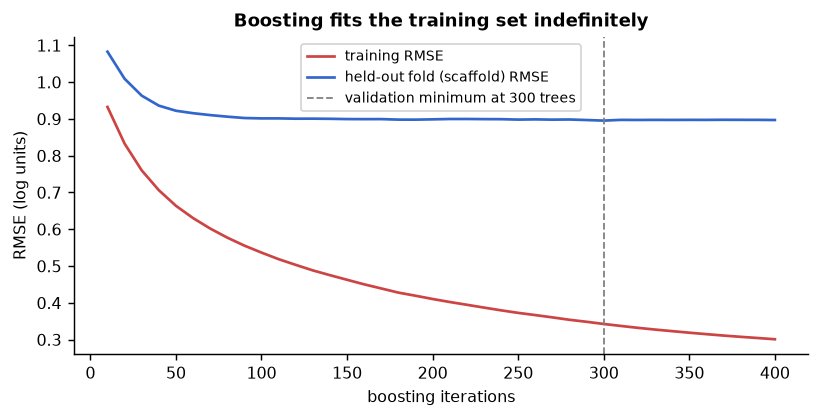

In [6]:
# Boosting on the real data, one stage at a time: training and scaffold-validation error per iteration.
from sklearn.model_selection import train_test_split
tr_idx, te_idx = next(GroupKFold(5).split(X, y, groups=scaffold))
stage_tr, stage_te = [], []
model = lgb.LGBMRegressor(n_estimators=400, learning_rate=0.05, num_leaves=31, verbose=-1, n_jobs=4)
model.fit(X[tr_idx], y[tr_idx])
for k in range(10, 401, 10):
    p_tr = model.predict(X[tr_idx], num_iteration=k)
    p_te = model.predict(X[te_idx], num_iteration=k)
    stage_tr.append(np.sqrt(mean_squared_error(y[tr_idx], p_tr)))
    stage_te.append(np.sqrt(mean_squared_error(y[te_idx], p_te)))
ks = np.arange(10, 401, 10)
fig, ax = plt.subplots(figsize=(6.4, 3.3))
ax.plot(ks, stage_tr, color="#c44", label="training RMSE")
ax.plot(ks, stage_te, color="#36c", label="held-out fold (scaffold) RMSE")
best_k = int(ks[int(np.argmin(stage_te))])
ax.axvline(best_k, color="grey", ls="--", lw=1, label=f"validation minimum at {best_k} trees")
ax.set_xlabel("boosting iterations"); ax.set_ylabel("RMSE (log units)")
ax.set_title("Boosting fits the training set indefinitely"); ax.legend(fontsize=7.5)
fig.tight_layout()
print("training RMSE: %.3f at 10 trees -> %.3f at 400" % (stage_tr[0], stage_tr[-1]))
print("held-out RMSE: %.3f at 10 trees -> %.3f at %d (minimum) -> %.3f at 400"
      % (stage_te[0], min(stage_te), best_k, stage_te[-1]))

<p class="caption"><b>Figure 1.</b> Training and held-out error against the number of boosting iterations on one scaffold fold. The training curve decreases monotonically and would reach zero given enough trees — boosting has no built-in stopping point, which is its main practical difference from a random forest, where adding trees never hurts. The held-out curve falls steeply, reaches its minimum around the printed number of trees and then drifts upward: that drift is overfitting, and the standard remedy is <strong>early stopping</strong> on a validation fold (<code>callbacks=[lgb.early_stopping(50)]</code>), which is itself a hyperparameter choice that must be made inside the training fold.</p>

<div class="box key"><h4>Key idea</h4>
<p>A random forest is an ensemble of <em>independent</em> high-variance models and is tuned mainly for convenience; a boosted ensemble is a <em>sequential</em> fit whose capacity grows with every iteration, so it must be regularised — by the learning rate, the tree size, the subsampling, the L1/L2 penalties and the stopping rule. That is why boosting usually wins after tuning and often loses before it.</p></div>

## 3. Three implementations of the same idea

Modern gradient boosting comes in three widely used implementations, all of which bin the features into histograms so that split-finding costs O(bins) rather than O(rows).

- **scikit-learn's `HistGradientBoosting`**<sup class="c"><a href="#r26">[26]</a></sup> — no extra dependency, the same API as everything else, good defaults.
- **XGBoost**<sup class="c"><a href="#r7">[7]</a></sup> — depth-wise growth, explicit L1/L2 regularisation, sparsity-aware splits, the implementation that made boosting the default for tabular competitions.
- **LightGBM**<sup class="c"><a href="#r8">[8]</a></sup> — leaf-wise growth (it expands the leaf with the largest loss reduction rather than a whole level), gradient-based sampling, usually the fastest on small and medium tables.

They differ in speed and in default behaviour far more than in attainable accuracy<sup class="c"><a href="#r9">[9]</a></sup>; CatBoost<sup class="c"><a href="#r10">[10]</a></sup> adds ordered boosting and native categorical handling, which matter for tables with many categorical columns. Boosted trees on descriptor matrices have been a standard QSAR tool since Sheridan's systematic comparison<sup class="c"><a href="#r21">[21]</a></sup>.

In [7]:
# Four untuned boosters and the forest, under the same scaffold cross-validation. (~45 s)
from sklearn.ensemble import HistGradientBoostingRegressor
rows = []
for name, est in [("random forest (300)", RandomForestRegressor(n_estimators=300, random_state=0, n_jobs=4)),
                  ("HistGradientBoosting (defaults)", HistGradientBoostingRegressor(random_state=0)),
                  ("XGBoost (300 trees, defaults)", xgb.XGBRegressor(n_estimators=300, tree_method="hist",
                                                                     random_state=0, n_jobs=4, verbosity=0)),
                  ("LightGBM (300 trees, defaults)", lgb.LGBMRegressor(n_estimators=300, random_state=0,
                                                                       n_jobs=4, verbose=-1))]:
    t0 = time.time()
    s = cross_validate(est, X, y, cv=GroupKFold(5), groups=scaffold,
                       scoring="neg_root_mean_squared_error", return_train_score=True)
    rows.append({"model": name, "scaffold_RMSE": -s["test_score"].mean(), "sd": s["test_score"].std(),
                 "train_RMSE": -s["train_score"].mean(), "seconds_total": time.time() - t0})
impl = pd.DataFrame(rows).set_index("model").round(3)
impl

,scaffold_RMSE,sd,train_RMSE,seconds_total
model,,,,
random forest (300),0.879,0.032,0.334,9.368
HistGradientBoosting (defaults),0.892,0.030,0.406,8.917
"XGBoost (300 trees, defaults)",0.929,0.034,0.179,2.196
"LightGBM (300 trees, defaults)",0.896,0.023,0.240,3.216


<p class="caption"><b>Table (Section 3).</b> Untuned ensembles under the scaffold split. The random forest (about 0.88) is the best of the four, HistGradientBoosting and LightGBM follow at about 0.89, and XGBoost with 300 default trees is clearly worse at about 0.93 — its default learning rate of 0.3 with 300 iterations simply overfits, as the training-error column confirms. The timing column shows the other axis, and it does not favour whoever you expected: XGBoost fits all five folds in under three seconds and LightGBM in four or five, while the random forest and scikit-learn's HistGradientBoosting both take nine or ten on this small, dense table. For a search of hundreds of fits that three- to four-fold ratio is what decides whether the search fits in a coffee break or a night, which is why the searches below use LightGBM. The practical reading is not "forests beat boosters" — it is <strong>that untuned boosting is not a result</strong>. Section 5 tunes it.</p>

## 4. Diagnosing with curves

### 4.1 Validation curves: one hyperparameter at a time

learning rate: best 0.03 at validation RMSE 0.882 (training 0.392); worst setting 0.959
num_leaves   : best 15 at validation RMSE 0.885 (training 0.456); worst setting 0.957
spread between the best and the second-best learning rate: 0.0035 log units


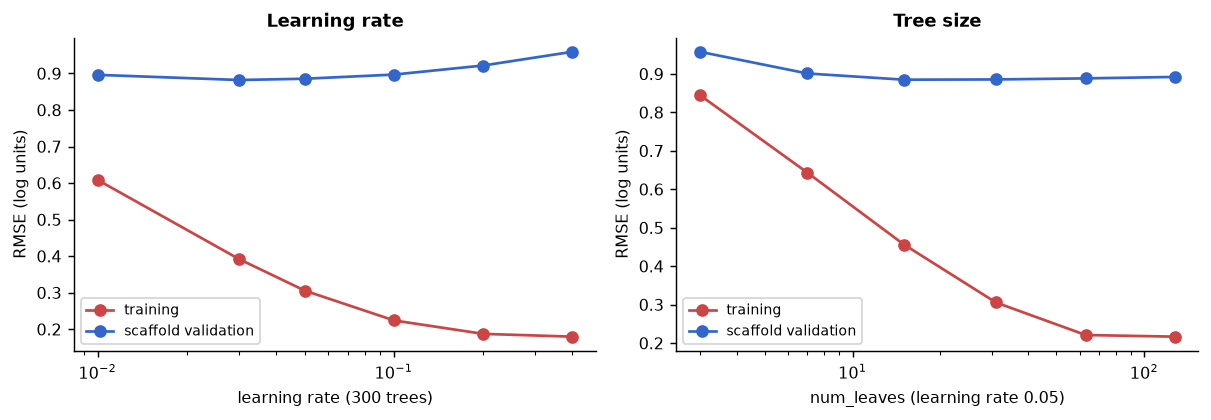

In [8]:
# Validation curves for the two hyperparameters that matter most. (~45 s)
from sklearn.model_selection import validation_curve
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.3))
lrs = [0.01, 0.03, 0.05, 0.1, 0.2, 0.4]
tr_s, te_s = validation_curve(lgb.LGBMRegressor(n_estimators=300, verbose=-1, n_jobs=4, random_state=0),
                              X, y, param_name="learning_rate", param_range=lrs, cv=GroupKFold(3),
                              groups=scaffold, scoring="neg_root_mean_squared_error")
axes[0].semilogx(lrs, -tr_s.mean(1), "o-", color="#c44", label="training")
axes[0].semilogx(lrs, -te_s.mean(1), "o-", color="#36c", label="scaffold validation")
axes[0].set_xlabel("learning rate (300 trees)"); axes[0].set_ylabel("RMSE (log units)")
axes[0].set_title("Learning rate"); axes[0].legend(fontsize=7.5)
leaves = [3, 7, 15, 31, 63, 127]
tr_l, te_l = validation_curve(lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05, verbose=-1, n_jobs=4, random_state=0),
                              X, y, param_name="num_leaves", param_range=leaves, cv=GroupKFold(3),
                              groups=scaffold, scoring="neg_root_mean_squared_error")
axes[1].semilogx(leaves, -tr_l.mean(1), "o-", color="#c44", label="training")
axes[1].semilogx(leaves, -te_l.mean(1), "o-", color="#36c", label="scaffold validation")
axes[1].set_xlabel("num_leaves (learning rate 0.05)"); axes[1].set_ylabel("RMSE (log units)")
axes[1].set_title("Tree size"); axes[1].legend(fontsize=7.5)
fig.tight_layout()
val_lr, val_lv = -te_s.mean(1), -te_l.mean(1)          # back to positive RMSE
i_lr, i_lv = int(np.argmin(val_lr)), int(np.argmin(val_lv))
print("learning rate: best %.2f at validation RMSE %.3f (training %.3f); worst setting %.3f"
      % (lrs[i_lr], val_lr[i_lr], -tr_s.mean(1)[i_lr], val_lr.max()))
print("num_leaves   : best %d at validation RMSE %.3f (training %.3f); worst setting %.3f"
      % (leaves[i_lv], val_lv[i_lv], -tr_l.mean(1)[i_lv], val_lv.max()))
print("spread between the best and the second-best learning rate: %.4f log units"
      % (np.sort(val_lr)[1] - np.sort(val_lr)[0]))

<p class="caption"><b>Figure 2.</b> Validation curves for the learning rate (left) and tree size (right) of LightGBM with 300 trees, under three scaffold folds. Both have the classic U shape in the validation curve and a monotone decreasing training curve: too small a learning rate underfits in 300 iterations, too large overfits; too few leaves underfit, too many overfit. The minima are printed under the figure. Note how <em>flat</em> the bottom of each curve is — the difference between the best and the second-best setting is a few thousandths of a log unit, far below the fold-to-fold standard deviation of about 0.03 from Section 1. This flatness is the most important practical fact about hyperparameter tuning on datasets of this size, and the reason the elaborate searches of Section 5 buy so little.</p>

### 4.2 Learning curves: would more compounds help?

LightGBM (lr 0.05, 300)    at the largest training size: validation RMSE 0.889 | training RMSE 0.307 | gap 0.582
random forest (200)        at the largest training size: validation RMSE 0.893 | training RMSE 0.337 | gap 0.557
training sizes used: [ 368  736 1105 1473 1842]


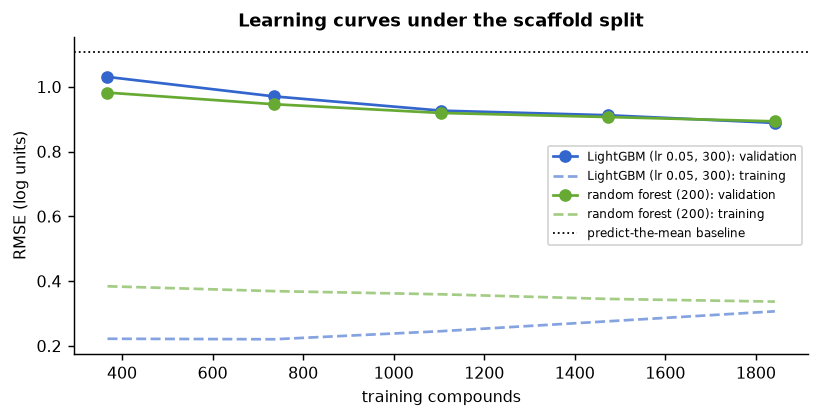

In [9]:
# Learning curve of the tuned-ish booster and of the forest, under scaffold folds. (~40 s)
from sklearn.model_selection import learning_curve
fig, ax = plt.subplots(figsize=(6.4, 3.3))
lc_final = {}
for name, est, col in [("LightGBM (lr 0.05, 300)", lgb.LGBMRegressor(n_estimators=300, learning_rate=0.05,
                                                                     verbose=-1, n_jobs=4, random_state=0), "#36c"),
                       ("random forest (200)", RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=4), "#6a3")]:
    sizes, tr_sc, te_sc = learning_curve(est, X, y, cv=GroupKFold(3), groups=scaffold,
                                         train_sizes=np.linspace(0.2, 1.0, 5),
                                         scoring="neg_root_mean_squared_error")
    ax.plot(sizes, -te_sc.mean(1), "o-", color=col, label=f"{name}: validation")
    ax.plot(sizes, -tr_sc.mean(1), "--", color=col, alpha=0.6, label=f"{name}: training")
    lc_final[name] = (float(-te_sc.mean(1)[-1]), float(-tr_sc.mean(1)[-1]))
ax.axhline(y.std(ddof=1), color="k", ls=":", lw=1, label="predict-the-mean baseline")
ax.set_xlabel("training compounds"); ax.set_ylabel("RMSE (log units)")
ax.set_title("Learning curves under the scaffold split"); ax.legend(fontsize=6.8)
fig.tight_layout()
for name, (v_end, t_end) in lc_final.items():
    print("%-26s at the largest training size: validation RMSE %.3f | training RMSE %.3f | gap %.3f"
          % (name, v_end, t_end, v_end - t_end))
print("training sizes used:", sizes)

<p class="caption"><b>Figure 3.</b> Learning curves for the booster and the forest under scaffold folds. Both validation curves fall with training-set size and are still falling at the right-hand edge, so more compounds would still help — but note how much shallower the decline is than under the random split of Unit 11: adding compounds from the <em>same</em> chemotypes improves interpolation quickly and extrapolation slowly. The dashed training curves show how hard both models fit what they have seen — training RMSE about 0.31 for the booster and 0.34 for the forest at the largest size, against validation values near 0.89 for both. The gap between the dashed and solid curves of the same colour, about 0.58 and 0.56 log units, is the variance component: these are high-capacity models on roughly 1,800 training compounds, and the scaffold split gives them no analogues to lean on.</p>

### 4.3 Bias and variance, measured

The decomposition $\mathbb{E}[(y - \hat{f}(x))^2] = \text{bias}^2 + \text{variance} + \sigma^2$ is usually drawn, rarely computed. On simulated data, where the true function is known, it can be measured directly: draw many training sets, fit the same learner to each, and compare the *average* prediction to the truth (bias) and the *spread* of predictions around that average (variance).

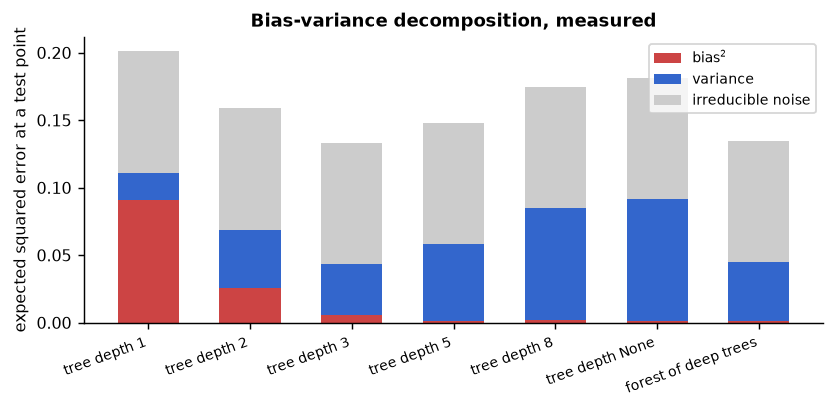

,bias2,variance,total_error
model,,,
tree depth 1,0.0905,0.0207,0.2012
tree depth 2,0.0260,0.0427,0.1587
tree depth 3,0.0056,0.0376,0.1332
tree depth 5,0.0010,0.0571,0.1482
tree depth 8,0.0018,0.0830,0.1748
tree depth None,0.0013,0.0902,0.1816
forest of deep trees,0.0012,0.0436,0.1348


In [10]:
# Bias-variance decomposition by simulation: tree depth, and what bagging does to it. (~10 s)
def truth(x):
    return np.sin(2 * np.pi * x) + 0.5 * x
rs = np.random.RandomState(0)
grid_x = np.linspace(0, 1, 200).reshape(-1, 1)
noise_sd = 0.3
rows = []
for depth in [1, 2, 3, 5, 8, None]:
    preds = []
    for _ in range(60):
        xb = rs.uniform(0, 1, 80).reshape(-1, 1)
        yb = truth(xb).ravel() + rs.normal(0, noise_sd, 80)
        preds.append(DecisionTreeRegressor(max_depth=depth, random_state=0).fit(xb, yb).predict(grid_x))
    P = np.array(preds)
    rows.append({"model": f"tree depth {depth}", "bias2": float(np.mean((P.mean(0) - truth(grid_x).ravel()) ** 2)),
                 "variance": float(np.mean(P.var(0)))})
preds = []
for _ in range(40):
    xb = rs.uniform(0, 1, 80).reshape(-1, 1)
    yb = truth(xb).ravel() + rs.normal(0, noise_sd, 80)
    preds.append(RandomForestRegressor(n_estimators=100, random_state=0).fit(xb, yb).predict(grid_x))
P = np.array(preds)
rows.append({"model": "forest of deep trees", "bias2": float(np.mean((P.mean(0) - truth(grid_x).ravel()) ** 2)),
             "variance": float(np.mean(P.var(0)))})
bv = pd.DataFrame(rows).set_index("model")
bv["total_error"] = bv["bias2"] + bv["variance"] + noise_sd ** 2
fig, ax = plt.subplots(figsize=(6.6, 3.2))
xp = np.arange(len(bv))
ax.bar(xp, bv["bias2"], 0.6, label="bias$^2$", color="#c44")
ax.bar(xp, bv["variance"], 0.6, bottom=bv["bias2"], label="variance", color="#36c")
ax.bar(xp, noise_sd ** 2, 0.6, bottom=bv["bias2"] + bv["variance"], label="irreducible noise", color="#ccc")
ax.set_xticks(xp); ax.set_xticklabels(bv.index, rotation=20, ha="right", fontsize=7.5)
ax.set_ylabel("expected squared error at a test point"); ax.set_title("Bias-variance decomposition, measured")
ax.legend(fontsize=7.5)
fig.tight_layout()
bv.round(4)

<p class="caption"><b>Figure 4 and table.</b> The decomposition computed, not asserted, on 60 simulated training sets of 80 points each. A stump has bias² ≈ 0.09 and variance ≈ 0.02 — it cannot represent the function; an unpruned tree has bias² ≈ 0.001 and variance ≈ 0.09 — it represents everything, including the noise. Total error is minimised in between, at depth 3 (about 0.13 against 0.20 for the stump and 0.18 for the unpruned tree). The last bar is the point of Section 1: a forest of <em>deep</em> trees keeps the low bias of the unpruned tree (0.001) and halves its variance (about 0.04), which is what "bagging reduces variance" means quantitatively. Boosting works from the other end — it starts with high-bias stumps and reduces bias step by step, which is why its characteristic failure is overfitting late rather than underfitting early.</p>

<div class="exercise"><h4>Exercise 1</h4>
<p>Repeat the simulation with 320 training points instead of 80 and with noise standard deviation 0.6 instead of 0.3. Which column changes with the sample size and which with the noise? Predict the answer before running it, then check whether the optimal depth moves.</p></div>

## 5. Hyperparameter search under a fixed budget

Three strategies, one budget of **20 configurations**, one search space, the same three scaffold folds, the same seed.

- **Grid search** evaluates a Cartesian product. With 20 evaluations you can afford three values of three parameters — and you have decided in advance that the other four parameters keep their defaults.
- **Random search** samples configurations from distributions over *all* parameters. Bergstra and Bengio's argument is geometric: when only a few parameters matter, a grid wastes its budget re-testing the same values of the important one, while random sampling gives 20 distinct values of every parameter<sup class="c"><a href="#r11">[11]</a></sup>.
- **Bayesian optimisation** fits a surrogate model of the score as a function of the parameters and samples where the expected improvement is highest<sup class="c"><a href="#r12">[12]</a></sup>. Optuna implements this with a tree-structured Parzen estimator, and adds **pruning**: a trial whose intermediate results are already worse than the running median is abandoned before it finishes<sup class="c"><a href="#r13">[13]</a></sup>. Hyperband-style schemes make the same bet with a different schedule<sup class="c"><a href="#r14">[14]</a></sup>.

In [11]:
# A single evaluation function used by all three searches: 3-fold scaffold CV of LightGBM.
folds = list(GroupKFold(3).split(X, y, groups=scaffold))
def evaluate(params, trial=None):
    '''Mean RMSE over the three scaffold folds; reports intermediate values so Optuna can prune.'''
    errs = []
    for i, (tr, te) in enumerate(folds):
        m = lgb.LGBMRegressor(random_state=0, n_jobs=4, verbose=-1, **params).fit(X[tr], y[tr])
        errs.append(np.sqrt(mean_squared_error(y[te], m.predict(X[te]))))
        if trial is not None:
            trial.report(float(np.mean(errs)), i)
            if trial.should_prune():
                raise optuna.TrialPruned()
    return float(np.mean(errs))
t0 = time.time()
default_rmse = evaluate({})
print("LightGBM defaults, 3-fold scaffold CV: RMSE %.4f  (%.1f s)" % (default_rmse, time.time() - t0))
print("budget for every search below: 20 configurations x 3 folds")

LightGBM defaults, 3-fold scaffold CV: RMSE 0.8880  (1.1 s)
budget for every search below: 20 configurations x 3 folds


In [12]:
# Grid search: 20 evaluations buys three parameters at three values (27 > 20, so 2 x 3 x 3 = 18). (~35 s)
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV
t0 = time.time()
grid = GridSearchCV(lgb.LGBMRegressor(random_state=0, n_jobs=4, verbose=-1),
                    {"n_estimators": [200, 600], "learning_rate": [0.02, 0.05, 0.1], "num_leaves": [7, 15, 31]},
                    cv=GroupKFold(3), scoring="neg_root_mean_squared_error").fit(X, y, groups=scaffold)
grid_time = time.time() - t0
print("grid search: 18 configurations in %.0f s" % grid_time)
print("  best RMSE %.4f with %s" % (-grid.best_score_, grid.best_params_))
res = pd.DataFrame(grid.cv_results_)
print("  spread of the 18 configurations: %.4f (best) to %.4f (worst)"
      % (-res["mean_test_score"].max(), -res["mean_test_score"].min()))

grid search: 18 configurations in 40 s
  best RMSE 0.8839 with {'learning_rate': 0.05, 'n_estimators': 200, 'num_leaves': 31}
  spread of the 18 configurations: 0.8839 (best) to 0.9428 (worst)


In [13]:
# Random search over seven parameters, same budget. (~55 s)
space = {"n_estimators": [100, 200, 300, 400, 600], "learning_rate": [0.01, 0.02, 0.05, 0.1, 0.2],
         "num_leaves": [7, 15, 31, 63], "min_child_samples": [5, 10, 20, 40, 80],
         "subsample": [0.6, 0.8, 1.0], "subsample_freq": [1], "colsample_bytree": [0.4, 0.6, 0.8, 1.0],
         "reg_lambda": [0.0, 0.1, 1.0, 10.0]}
t0 = time.time()
rand = RandomizedSearchCV(lgb.LGBMRegressor(random_state=0, n_jobs=4, verbose=-1), space, n_iter=20,
                          cv=GroupKFold(3), scoring="neg_root_mean_squared_error",
                          random_state=0).fit(X, y, groups=scaffold)
rand_time = time.time() - t0
print("random search: 20 configurations in %.0f s" % rand_time)
print("  best RMSE %.4f" % -rand.best_score_)
print("  chosen:", {k: v for k, v in sorted(rand.best_params_.items())})

random search: 20 configurations in 29 s
  best RMSE 0.8746
  chosen: {'colsample_bytree': 0.4, 'learning_rate': 0.05, 'min_child_samples': 10, 'n_estimators': 200, 'num_leaves': 63, 'reg_lambda': 1.0, 'subsample': 1.0, 'subsample_freq': 1}


In [14]:
# Bayesian optimisation with pruning, same budget of 20 trials. (~60 s)
def objective(trial):
    params = dict(n_estimators=trial.suggest_int("n_estimators", 100, 600, step=100),
                  learning_rate=trial.suggest_float("learning_rate", 0.01, 0.2, log=True),
                  num_leaves=trial.suggest_int("num_leaves", 7, 63, log=True),
                  min_child_samples=trial.suggest_int("min_child_samples", 5, 80, log=True),
                  subsample=trial.suggest_float("subsample", 0.6, 1.0), subsample_freq=1,
                  colsample_bytree=trial.suggest_float("colsample_bytree", 0.4, 1.0),
                  reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 20.0, log=True))
    return evaluate(params, trial=trial)
t0 = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=0),
                            pruner=optuna.pruners.MedianPruner(n_startup_trials=5, n_warmup_steps=1))
study.optimize(objective, n_trials=20, show_progress_bar=False)
opt_time = time.time() - t0
pruned = sum(t.state == optuna.trial.TrialState.PRUNED for t in study.trials)
print("Optuna (TPE + median pruning): 20 trials in %.0f s, %d pruned early" % (opt_time, pruned))
print("  best RMSE %.4f" % study.best_value)
print("  chosen:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in sorted(study.best_params.items())})

Optuna (TPE + median pruning): 20 trials in 72 s, 6 pruned early
  best RMSE 0.8692
  chosen: {'colsample_bytree': 0.4066, 'learning_rate': 0.012, 'min_child_samples': 6, 'n_estimators': 500, 'num_leaves': 55, 'reg_lambda': 1.3183, 'subsample': 0.9331}


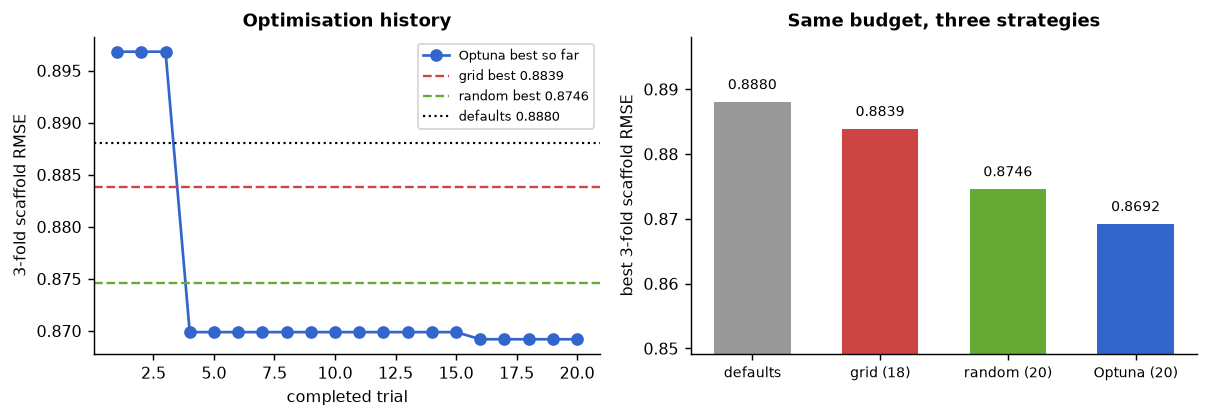

,best_RMSE,seconds
search,,
defaults,0.8880,0.0000
grid (18),0.8839,40.4515
random (20),0.8746,29.2726
Optuna (20),0.8692,72.4831


In [15]:
# The three searches side by side: what each bought for the same number of evaluations.
hist = [t.value for t in study.trials if t.value is not None]
running = np.minimum.accumulate(hist)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.3))
axes[0].plot(range(1, len(running) + 1), running, "o-", color="#36c", label="Optuna best so far")
axes[0].axhline(-grid.best_score_, color="#c44", ls="--", lw=1.3, label=f"grid best {-grid.best_score_:.4f}")
axes[0].axhline(-rand.best_score_, color="#6a3", ls="--", lw=1.3, label=f"random best {-rand.best_score_:.4f}")
axes[0].axhline(default_rmse, color="k", ls=":", lw=1.2, label=f"defaults {default_rmse:.4f}")
axes[0].set_xlabel("completed trial"); axes[0].set_ylabel("3-fold scaffold RMSE")
axes[0].set_title("Optimisation history"); axes[0].legend(fontsize=7)
summary = pd.DataFrame({"search": ["defaults", "grid (18)", "random (20)", "Optuna (20)"],
                        "best_RMSE": [default_rmse, -grid.best_score_, -rand.best_score_, study.best_value],
                        "seconds": [0.0, grid_time, rand_time, opt_time]}).set_index("search")
axes[1].bar(range(4), summary["best_RMSE"], color=["#999", "#c44", "#6a3", "#36c"], width=0.6)
axes[1].set_ylim(min(summary["best_RMSE"]) - 0.02, max(summary["best_RMSE"]) + 0.01)
axes[1].set_xticks(range(4)); axes[1].set_xticklabels(summary.index, fontsize=8)
axes[1].set_ylabel("best 3-fold scaffold RMSE"); axes[1].set_title("Same budget, three strategies")
for i, v in enumerate(summary["best_RMSE"]):
    axes[1].text(i, v + 0.002, f"{v:.4f}", ha="center", fontsize=8)
fig.tight_layout()
summary.round(4)

<p class="caption"><b>Figure 5 and table.</b> One budget, three strategies, on the same folds. The grid improves on the defaults only slightly, because 18 evaluations buy three values of three parameters and leave the other four at their defaults. Random search, sampling all seven parameters, does better with the same number of fits — the Bergstra–Bengio result reproduced on our data<sup class="c"><a href="#r11">[11]</a></sup>. Optuna's tree-structured Parzen estimator does better still and, because the median pruner abandoned the printed number of hopeless trials after one or two folds, it spent part of its budget on configurations rather than on finishing bad ones. <strong>And the whole exercise moves the RMSE by a few hundredths of a log unit</strong> — less than the fold-to-fold standard deviation of about 0.03. That is the honest summary of hyperparameter tuning for a dataset of this size: it is worth doing once, properly and reproducibly, and it is not where the accuracy comes from.</p>

### 5.1 The number you may report

`study.best_value` is the best of 20 noisy estimates: the winner's curse of Unit 12 applies, and quoting it as the model's performance is the most common tuning error in the literature<sup class="c"><a href="#r15">[15]</a></sup>. The honest estimate puts the *whole search* inside an outer loop — nested cross-validation with a fixed inner budget, so that the thing being assessed is "LightGBM plus a 8-configuration random search", not "the configuration that happened to win".

In [16]:
# Nested cross-validation: the search is re-run inside every outer fold. (~35 s)
inner_search = RandomizedSearchCV(lgb.LGBMRegressor(random_state=0, n_jobs=4, verbose=-1), space, n_iter=8,
                                  cv=GroupKFold(2), scoring="neg_root_mean_squared_error", random_state=0)
outer_scores, inner_scores, chosen = [], [], []
for tr, te in GroupKFold(3).split(X, y, groups=scaffold):
    inner_search.fit(X[tr], y[tr], groups=scaffold[tr])
    inner_scores.append(-inner_search.best_score_)
    chosen.append(inner_search.best_params_["learning_rate"])
    outer_scores.append(np.sqrt(mean_squared_error(y[te], inner_search.best_estimator_.predict(X[te]))))
print("single-level search, best reported score   : %.4f   <- optimistic: it is the maximum of 20 estimates"
      % study.best_value)
print("nested CV, outer estimate of the procedure : %.4f  (folds %s)"
      % (np.mean(outer_scores), np.round(outer_scores, 3)))
print("difference (optimism of the quoted best)   : %.4f log units" % (np.mean(outer_scores) - study.best_value))
print("inner best scores (trained on 2/3 of the data, 2 folds): %s - pessimistic for the opposite reason"
      % np.round(inner_scores, 3))
print("learning rate chosen in each outer fold:", chosen)

single-level search, best reported score   : 0.8692   <- optimistic: it is the maximum of 20 estimates
nested CV, outer estimate of the procedure : 0.8773  (folds [0.89  0.848 0.894])
difference (optimism of the quoted best)   : 0.0081 log units
inner best scores (trained on 2/3 of the data, 2 folds): [0.929 0.935 0.925] - pessimistic for the opposite reason
learning rate chosen in each outer fold: [0.05, 0.05, 0.02]


Three numbers, three meanings. The single-level search reports about 0.869 — the best of twenty noisy estimates on the same folds it optimised. The nested estimate of the whole procedure is about 0.877, so the quoted best is optimistic by roughly 0.008 log units. The inner scores are *worse* than both (about 0.93), because each inner search trains on two thirds of the data split into two folds: a smaller training set gives a worse model, which is the standard pessimistic bias of cross-validation and the reason the inner score must never be reported either. The number that belongs in a paper is the nested one, together with the search space and the budget.

<div class="box warn"><h4>What tuning cannot fix</h4>
<p>Compare the whole of Section 5 with Unit 11's table: changing the representation from 11 descriptors to 2,048 fingerprint bits moved RMSE by about 0.15 log units, and changing the split from random to scaffold moved it by about 0.07. Twenty tuning trials moved it by about 0.02. Spend the project's effort in that order — data, representation, validation design — and tune last.</p></div>

## 6. Class imbalance: weights, thresholds, and what each costs

Make the ROCK1 classification problem realistic for screening by sub-sampling the actives to 5%, then apply the two standard remedies: weighting the classes in the loss and moving the decision threshold<sup class="c"><a href="#r18">[18]</a></sup>. A third family, synthetic over-sampling of the minority class such as SMOTE<sup class="c"><a href="#r25">[25]</a></sup>, interpolates new positives between existing ones; it is popular, it must be applied inside the training fold only, and on molecular data it manufactures feature vectors that correspond to no molecule.

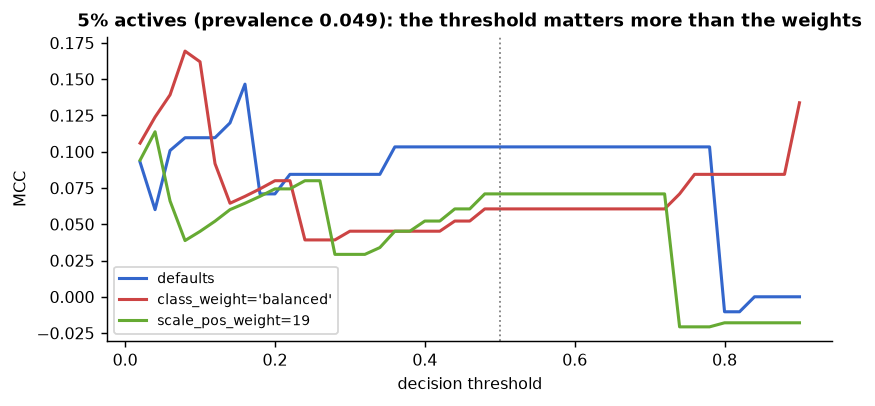

,ROC_AUC,PR_AUC,MCC@0.5,best_threshold,MCC@best,Brier
model,,,,,,
defaults,0.712,0.127,0.103,0.16,0.147,0.049
class_weight='balanced',0.710,0.156,0.061,0.08,0.169,0.053
scale_pos_weight=19,0.711,0.109,0.071,0.04,0.114,0.055


In [17]:
# Class weighting and threshold tuning on a 5%-active version of the problem.
from sklearn.metrics import (roc_auc_score, average_precision_score, matthews_corrcoef,
                             brier_score_loss, precision_score, recall_score)
rs = np.random.RandomState(0)
act, ina = np.where(y_cls == 1)[0], np.where(y_cls == 0)[0]
rare = np.concatenate([ina, rs.choice(act, int(0.05 / 0.95 * len(ina)), replace=False)])
tr_i, te_i = train_test_split(rare, test_size=0.25, random_state=0, stratify=y_cls[rare])
rows, curves = [], {}
for name, est in [("defaults", lgb.LGBMClassifier(random_state=0, n_jobs=4, verbose=-1)),
                  ("class_weight='balanced'", lgb.LGBMClassifier(random_state=0, n_jobs=4, verbose=-1,
                                                                 class_weight="balanced")),
                  ("scale_pos_weight=19", lgb.LGBMClassifier(random_state=0, n_jobs=4, verbose=-1,
                                                             scale_pos_weight=19))]:
    p = est.fit(X[tr_i], y_cls[tr_i]).predict_proba(X[te_i])[:, 1]
    ths = np.linspace(0.02, 0.9, 45)
    mccs = [matthews_corrcoef(y_cls[te_i], (p >= t).astype(int)) for t in ths]
    curves[name] = (ths, mccs)
    best_t = float(ths[int(np.argmax(mccs))])
    rows.append({"model": name, "ROC_AUC": roc_auc_score(y_cls[te_i], p),
                 "PR_AUC": average_precision_score(y_cls[te_i], p),
                 "MCC@0.5": matthews_corrcoef(y_cls[te_i], (p >= 0.5).astype(int)),
                 "best_threshold": best_t, "MCC@best": max(mccs),
                 "Brier": brier_score_loss(y_cls[te_i], p)})
imb = pd.DataFrame(rows).set_index("model").round(3)
fig, ax = plt.subplots(figsize=(6.6, 3.2))
for (name, (ths, mccs)), col in zip(curves.items(), ["#36c", "#c44", "#6a3"]):
    ax.plot(ths, mccs, lw=1.7, color=col, label=name)
ax.axvline(0.5, color="grey", ls=":", lw=1)
ax.set_xlabel("decision threshold"); ax.set_ylabel("MCC")
ax.set_title(f"5% actives (prevalence {y_cls[te_i].mean():.3f}): the threshold matters more than the weights")
ax.legend(fontsize=7.5)
fig.tight_layout()
imb

<p class="caption"><b>Figure 6 and table.</b> Three ways to treat a 5%-active problem. The three models have practically the same ROC-AUC (about 0.71), so class weighting does <em>not</em> improve discrimination — it rescales the predicted probabilities, which is why the Brier score gets <em>worse</em> (from about 0.049 to 0.053 and 0.055) and the optimal threshold moves far below 0.5. What does change the usable performance is the threshold itself: for the unweighted model MCC rises from about 0.10 at the default 0.5 to about 0.15 at its optimum near 0.16. The lesson, which the clinical-prediction literature states forcefully<sup class="c"><a href="#r18">[18]</a></sup>, is that imbalance corrections are a threshold decision in disguise: fit an unweighted, calibrated model and then choose the operating point from the costs, rather than distorting the likelihood and keeping an arbitrary cut-off.</p>

## 7. Monotonic constraints: putting chemistry into the model

Sometimes the direction of an effect is known in advance and the data are too sparse to establish it. A model that predicts a *lower* potency for a compound more similar to the known actives is contradicting the similar-property principle, and a referee will say so. Gradient-boosting implementations can enforce monotonicity in a feature: every split is constrained so that the prediction is non-decreasing (or non-increasing) along it<sup class="c"><a href="#r19">[19]</a></sup>.

The experiment below adds one feature — the Tanimoto similarity to the 100 most potent *training* compounds, recomputed inside each fold so that no test information leaks — and fits HistGradientBoosting with and without the constraint that predictions increase with it.

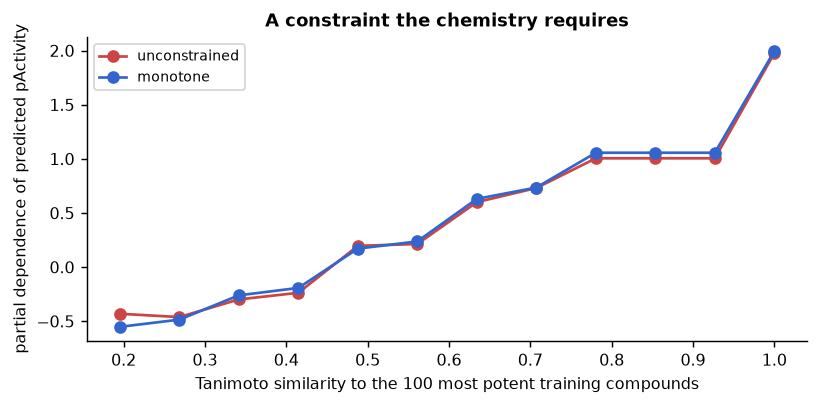

,scaffold_RMSE,sd
model,,
unconstrained,0.859,0.022
monotone increasing in similarity,0.851,0.014


In [18]:
# A domain-motivated monotone feature, with and without the constraint. (~30 s)
from sklearn.inspection import partial_dependence
def similarity_to_top_actives(train_idx, query_idx, n_top=100):
    '''Max Tanimoto similarity to the n_top most potent TRAINING compounds (no test information used).'''
    top = train_idx[np.argsort(-y[train_idx])[:n_top]]
    ref = [fps[i] for i in top]
    return np.array([max(DataStructs.BulkTanimotoSimilarity(fps[i], ref)) for i in query_idx])
folds3 = list(GroupKFold(3).split(X, y, groups=scaffold))
rows = []
for label, cst in [("unconstrained", None), ("monotone increasing in similarity", [0] * X.shape[1] + [1])]:
    errs = []
    for tr, te in folds3:
        Xtr = np.column_stack([X[tr], similarity_to_top_actives(tr, tr)])
        Xte = np.column_stack([X[te], similarity_to_top_actives(tr, te)])
        m = HistGradientBoostingRegressor(random_state=0, max_iter=150, monotonic_cst=cst).fit(Xtr, y[tr])
        errs.append(np.sqrt(mean_squared_error(y[te], m.predict(Xte))))
    rows.append({"model": label, "scaffold_RMSE": float(np.mean(errs)), "sd": float(np.std(errs))})
tr0, te0 = folds3[0]
Xtr0 = np.column_stack([X[tr0], similarity_to_top_actives(tr0, tr0)])
fig, ax = plt.subplots(figsize=(6.4, 3.2))
for label, cst, col in [("unconstrained", None, "#c44"), ("monotone", [0] * X.shape[1] + [1], "#36c")]:
    m = HistGradientBoostingRegressor(random_state=0, max_iter=150, monotonic_cst=cst).fit(Xtr0, y[tr0])
    pdp = partial_dependence(m, Xtr0, [X.shape[1]], grid_resolution=12)
    ax.plot(pdp["grid_values"][0], pdp["average"][0], "o-", color=col, label=label)
ax.set_xlabel("Tanimoto similarity to the 100 most potent training compounds")
ax.set_ylabel("partial dependence of predicted pActivity")
ax.set_title("A constraint the chemistry requires"); ax.legend(fontsize=7.5)
fig.tight_layout()
pd.DataFrame(rows).set_index("model").round(3)

<p class="caption"><b>Figure 7 and table.</b> The partial-dependence curve of the similarity feature, with and without the monotone constraint, and the cross-validated cost of imposing it. The unconstrained curve is already close to monotone — the data do support the similar-property principle — but it dips in places where few compounds live, and those dips are noise the model would happily extrapolate. The constrained model removes them at no cost in accuracy (RMSE about 0.85 against 0.86 unconstrained, with a smaller fold-to-fold spread). This is the general shape of a good constraint: it encodes knowledge the data cannot contradict, buys robustness where data are thin, and should be reported as a modelling choice in the Methods.</p>

<div class="exercise"><h4>Exercise 2</h4>
<p>Impose the <em>wrong</em> constraint: require the prediction to be monotone <strong>decreasing</strong> in the same similarity feature. Measure the scaffold RMSE and plot the partial dependence. How large is the penalty, and what does the size of that penalty tell you about how strongly the data support the correct direction?</p></div>

## 8. The final model, and what it learned

tuned model on a held-out scaffold fold: RMSE 0.889 | predict-the-mean baseline 1.211
top five descriptors by gain: {'MaxPartialCharge': 0.086, 'MinPartialCharge': 0.056, 'MaxEStateIndex': 0.056, 'HallKierAlpha': 0.048, 'SlogP_VSA5': 0.043}


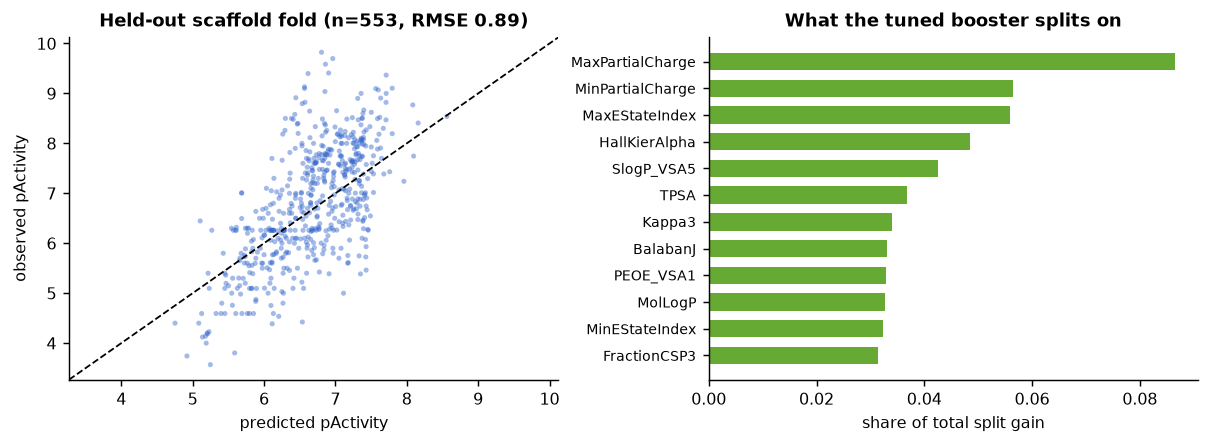

In [19]:
# Refit the selected configuration on four scaffold folds, score the fifth, and look at what it uses. (~10 s)
tr_f, te_f = next(GroupKFold(5).split(X, y, groups=scaffold))
final_model = lgb.LGBMRegressor(random_state=0, n_jobs=4, verbose=-1, **study.best_params).fit(X[tr_f], y[tr_f])
pred_f = final_model.predict(X[te_f])
rmse_f = float(np.sqrt(mean_squared_error(y[te_f], pred_f)))
fig, axes = plt.subplots(1, 2, figsize=(9.4, 3.5))
axes[0].scatter(pred_f, y[te_f], s=8, alpha=0.45, color="#36c", edgecolor="none")
lims = [y[te_f].min() - 0.3, y[te_f].max() + 0.3]
axes[0].plot(lims, lims, "k--", lw=1); axes[0].set_xlim(lims); axes[0].set_ylim(lims)
axes[0].set_xlabel("predicted pActivity"); axes[0].set_ylabel("observed pActivity")
axes[0].set_title(f"Held-out scaffold fold (n={len(te_f)}, RMSE {rmse_f:.2f})")
imp = pd.Series(final_model.booster_.feature_importance(importance_type="gain"), index=DESC_NAMES)
imp = (imp / imp.sum()).sort_values(ascending=False).head(12).iloc[::-1]
axes[1].barh(np.arange(len(imp)), imp.values, color="#6a3", height=0.65)
axes[1].set_yticks(np.arange(len(imp))); axes[1].set_yticklabels(imp.index, fontsize=7.5)
axes[1].set_xlabel("share of total split gain"); axes[1].set_title("What the tuned booster splits on")
fig.tight_layout()
print("tuned model on a held-out scaffold fold: RMSE %.3f | predict-the-mean baseline %.3f"
      % (rmse_f, float(np.sqrt(((y[te_f] - y[tr_f].mean()) ** 2).mean()))))
print("top five descriptors by gain:", {k: round(v, 3) for k, v in imp.iloc[::-1].head(5).items()})

<p class="caption"><b>Figure 8.</b> Left: observed against predicted potency for one held-out scaffold fold under the tuned configuration; the cloud is tilted towards the mean exactly as in Unit 11, and the printed RMSE is close to the nested estimate rather than to the search's best score. Right: the share of total split gain taken by each descriptor. The ranking is dominated by the extreme partial charges, the maximum E-state index, the Hall–Kier shape index and a surface-area descriptor — electronic and shape properties rather than bulk size, which is a reasonable chemical story for a kinase hinge binder and one to be read with the caution of Unit 13: gain importances are not causal, they are split frequencies weighted by improvement, and correlated descriptors divide the credit among themselves. Unit 16 replaces this bar chart with SHAP values<sup class="c"><a href="#r20">[20]</a></sup>, which at least attribute consistently.</p>

## 9. The paragraph that goes in the paper

A Methods section must let a reader reproduce the search, not merely admire the result; for clinical prediction models the same requirements are now codified in TRIPOD+AI<sup class="c"><a href="#r30">[30]</a></sup>. The cell below writes it from the objects created above, so no number in it can drift from the experiment.

In [20]:
# The Methods paragraph, generated from the actual run.
best = {k: (round(v, 4) if isinstance(v, float) else v) for k, v in sorted(study.best_params.items())}
methods = f'''Gradient-boosted regression trees (LightGBM {lgb.__version__}) were trained to predict pActivity
(-log10 M) from {X.shape[1]} RDKit descriptors for {len(y)} ROCK1 inhibitors with at least one exact measurement
(curated ChEMBL snapshot). Because the intended use is prospective prediction on new chemotypes, all
cross-validation was grouped by Bemis-Murcko scaffold ({len(set(scaffold))} groups); random splits were used only
for the out-of-bag comparison reported in the supplementary material. Hyperparameters were optimised with Optuna
{optuna.__version__} (tree-structured Parzen estimator, seed 0, median pruner with 5 start-up trials) over
{len(study.trials)} trials with a budget of three scaffold folds per trial, in the space:
n_estimators 100-600, learning_rate 0.01-0.2 (log), num_leaves 7-63 (log), min_child_samples 5-80 (log),
subsample 0.6-1.0, colsample_bytree 0.4-1.0, reg_lambda 1e-3 to 20 (log). {pruned} trials were pruned.
The selected configuration was {best}, with a cross-validated RMSE of {study.best_value:.3f} log units.
Because that value is the maximum of {len(study.trials)} correlated estimates, performance is reported from
nested cross-validation in which the search was repeated inside each of three outer scaffold folds
(8 random configurations per inner search): RMSE {np.mean(outer_scores):.3f} +- {np.std(outer_scores):.3f}
log units, against {default_rmse:.3f} for untuned LightGBM, {bag_tbl.loc["random forest, 300 trees", "scaffold_RMSE"]:.3f}
for an untuned random forest and {y.std(ddof=1):.3f} for predicting the training mean. Predictions were
constrained to increase monotonically with the Tanimoto similarity to the 100 most potent training compounds,
a feature recomputed within each training fold. All seeds were fixed at 0 and the complete search history is
available in the accompanying notebook.'''
print(methods)

Gradient-boosted regression trees (LightGBM 4.6.0) were trained to predict pActivity
(-log10 M) from 45 RDKit descriptors for 2764 ROCK1 inhibitors with at least one exact measurement
(curated ChEMBL snapshot). Because the intended use is prospective prediction on new chemotypes, all
cross-validation was grouped by Bemis-Murcko scaffold (1218 groups); random splits were used only
for the out-of-bag comparison reported in the supplementary material. Hyperparameters were optimised with Optuna
5.0.0 (tree-structured Parzen estimator, seed 0, median pruner with 5 start-up trials) over
20 trials with a budget of three scaffold folds per trial, in the space:
n_estimators 100-600, learning_rate 0.01-0.2 (log), num_leaves 7-63 (log), min_child_samples 5-80 (log),
subsample 0.6-1.0, colsample_bytree 0.4-1.0, reg_lambda 1e-3 to 20 (log). 6 trials were pruned.
The selected configuration was {'colsample_bytree': 0.4066, 'learning_rate': 0.012, 'min_child_samples': 6, 'n_estimators': 500, 'num_leav

Read that paragraph against what a typical paper says — "hyperparameters were optimised by grid search and the best model achieved R² = 0.X" — and the difference is the whole unit: the split, the budget, the space, the pruning, the seed, the nested estimate, the baselines, and the constraint.

<div class="box bridge"><h4>Bridge — where this unit sits</h4>
<p><a href="../U11_Supervised_Workflow/index.html">Unit 11</a> supplies the pipeline discipline every search here depends on, and <a href="../U12_Validation/index.html">Unit 12</a> the scaffold protocol, the nested-CV argument and the corrected test you would use to compare the tuned model against the forest; <a href="../U13_Features_Dimensionality/index.html">Unit 13</a> built the descriptor matrix and showed why tree ensembles tolerate irrelevant columns; <a href="../U16_Interpretability/index.html">Unit 16</a> opens the tuned ensemble with SHAP values<sup class="c"><a href="#r20">[20]</a></sup>; <a href="../U17_Uncertainty_AD/index.html">Unit 17</a> attaches conformal prediction intervals to it; <a href="../U18_Deep_Learning/index.html">Unit 18</a> asks whether a neural network can beat it on this table (the literature says usually not<sup class="c"><a href="#r16">[16]</a></sup>); <a href="../U25_Scaling_HPC/index.html">Unit 25</a> moves a search of this shape from a laptop to the cluster; and <a href="../U27_Capstone/index.html">Unit 27</a> assembles the whole chain. Decision trees, boosting as an optimisation algorithm and the bias-variance theory are treated from the machine-learning side in the artificial-intelligence course <a href="../../BGM411/Python/index.html">BGM411</a>; the QSAR tradition these models grew out of is <a href="../../Cheminformatics/U13_ML_Properties/index.html">Unit 13 of the cheminformatics course</a>.</p></div>

## 10. Summary

You should now be able to explain, without notes:

- how bagging reduces variance, why decorrelating trees matters, and what the out-of-bag estimate does and does not measure;
- the gradient-boosting recursion, traced by hand, and the role of the learning rate, the tree size, subsampling and regularisation;
- why untuned boosting can lose to an untuned forest, and why tuned boosting usually wins;
- how to read a validation curve and a learning curve, and what a measured bias–variance decomposition looks like;
- the three search strategies, why random beats grid at equal budget, what pruning buys, and how to report a search;
- why the best score of a search is not a performance estimate, and how nested cross-validation repairs it;
- what class weighting actually does under imbalance, and why the threshold is the real lever;
- when a monotonic constraint is justified and how to measure its cost;
- what belongs in the Methods paragraph.

The numbers to remember from this notebook: bagging 100 unpruned trees cuts the scaffold RMSE of a single tree from about 1.25 to about 0.88; untuned XGBoost at its default learning rate is the worst ensemble here (about 0.93); twenty trials of Bayesian search improve LightGBM from about 0.888 to about 0.87, while nested cross-validation puts the honest figure at about 0.877; class weighting leaves ROC-AUC at about 0.71 and worsens the Brier score, while moving the threshold raises MCC from about 0.10 to about 0.15.

## 11. Self-assessment

<details><summary>1. Why does averaging 100 unpruned trees beat one unpruned tree by so much?</summary>Because an unpruned tree has very low bias and very high variance, and averaging B models with pairwise correlation ρ reduces the variance to ρ + (1−ρ)/B of a single model's. The simulation in Section 4.3 measures it: variance about 0.09 for one deep tree, about 0.04 for a forest of them, with bias unchanged.</details>

<details><summary>2. Your forest's OOB R² is 0.48 and your scaffold-split R² is 0.30. Which do you report?</summary>The scaffold number, if the claim is about new chemotypes. OOB resamples rows at random, so it estimates the random-split quantity; it is excellent for cheap internal comparisons and misleading as a headline.</details>

<details><summary>3. You halve the learning rate of a boosted model. What else must change?</summary>The number of iterations, roughly doubled — the two are one hyperparameter in two coordinates. Everything else equal, a smaller learning rate with proportionally more trees usually generalises slightly better and costs proportionally more compute.</details>

<details><summary>4. Why does adding trees never hurt a random forest but can hurt a boosted model?</summary>Forest trees are fitted independently to bootstrap samples, so adding them only improves the average. Boosting fits each tree to the current residuals, so capacity grows with every iteration and late iterations start fitting noise — hence early stopping.</details>

<details><summary>5. Grid and random search get the same 20 evaluations. Why does random usually win?</summary>Because a grid spends its budget on a few values of every parameter jointly, re-testing the same value of the important parameter many times, while random sampling gives 20 distinct values of each parameter and covers the dimensions that matter. The advantage grows with the number of parameters that do not matter.</details>

<details><summary>6. What does Optuna's median pruner do, and what is the risk?</summary>It stops a trial whose intermediate score (here, after one or two folds) is worse than the median of completed trials at the same step, freeing budget for new configurations. The risk is pruning a configuration that starts badly and finishes well, which is why a warm-up of a few start-up trials and at least one completed step is standard.</details>

<details><summary>7. A paper reports "best cross-validated RMSE from a 500-point grid search". What is wrong with that number?</summary>It is the maximum of 500 correlated noisy estimates, so it is biased optimistically — the winner's curse. Our much smaller search is optimistic by about 0.008 log units; with 500 candidates and less data the bias is far larger. The remedy is nested cross-validation or a genuinely untouched test set.</details>

<details><summary>8. Your nested CV gives a worse score than your single-level search and your inner folds give a worse score still. Is something broken?</summary>No. The single-level best is optimistic (maximum of many estimates); the nested outer estimate is the honest one; the inner scores are pessimistic because they train on a fraction of a fraction of the data. Three estimators of three different quantities.</details>

<details><summary>9. When does class weighting help?</summary>When the loss really should weight the classes differently — for instance when the training sample under-represents the positive class relative to deployment. It does not improve ranking (ROC-AUC barely moves) and it degrades calibration, so if the goal is a usable probability plus a decision, prefer an unweighted model with a chosen threshold.</details>

<details><summary>10. Give an example of a monotonic constraint you could justify in this laboratory, and one you could not.</summary>Justified: predicted potency non-decreasing in similarity to known actives; predicted solubility non-increasing in logP. Not justified: potency monotone in molecular weight — larger is better only up to a point, and forcing monotonicity would encode a false belief that the data would otherwise contradict.</details>

<details><summary>11. You have a week of compute. Where do you spend it?</summary>Not on tuning. On more or better data, a better representation, and a validation design that answers the real question — those moved the error by 0.07–0.15 log units here, against about 0.02 for twenty tuning trials. Tune once at the end, with a stated budget and a nested estimate.</details>

<details><summary>12. What minimum information must a Methods section give about a hyperparameter search?</summary>The search space with its ranges and scales, the budget (number of configurations and the resampling used per configuration), the algorithm and its seed, the pruning or early-stopping rule, the selected configuration, and an estimate of performance that did not come from the search itself.</details>

## Glossary

<dl class="gloss">
<dt>Bagging</dt><dd>Fitting one learner to many bootstrap resamples and averaging, to reduce variance.</dd>
<dt>Bias–variance decomposition</dt><dd>Splitting expected squared error into systematic error, sensitivity to the training sample, and irreducible noise.</dd>
<dt>Boosting</dt><dd>Additive fitting in which each new small model is fitted to the residuals (negative gradient) of the current ensemble.</dd>
<dt>Colsample / subsample</dt><dd>Fractions of features and rows used per tree; stochastic regularisation of a boosted ensemble.</dd>
<dt>Early stopping</dt><dd>Halting boosting when a validation score stops improving; a hyperparameter chosen inside the training fold.</dd>
<dt>Learning rate (shrinkage)</dt><dd>The factor ν by which each boosting step is multiplied before being added to the ensemble.</dd>
<dt>Leaf-wise vs depth-wise growth</dt><dd>LightGBM expands the leaf with the largest loss reduction; XGBoost grows whole levels.</dd>
<dt>Monotonic constraint</dt><dd>A restriction forcing predictions to be non-decreasing (or non-increasing) in a chosen feature.</dd>
<dt>Nested cross-validation</dt><dd>An outer loop assessing a procedure whose inner loop performs the hyperparameter selection.</dd>
<dt>Out-of-bag (OOB) estimate</dt><dd>Prediction of each row by the bootstrap trees that did not see it; a free random-resampling validation score.</dd>
<dt>Pruning (Optuna)</dt><dd>Abandoning a trial whose intermediate results are already uncompetitive.</dd>
<dt>Random forest</dt><dd>Bagged trees whose splits consider a random subset of features, reducing inter-tree correlation.</dd>
<dt>Scale_pos_weight / class_weight</dt><dd>Loss weights that compensate class imbalance; they rescale probabilities rather than improve ranking.</dd>
<dt>Search budget</dt><dd>The number of configurations and the resampling cost per configuration that a search is allowed.</dd>
<dt>TPE (tree-structured Parzen estimator)</dt><dd>The Bayesian sampler used by Optuna, modelling good and bad regions of the search space separately.</dd>
<dt>Validation curve</dt><dd>Training and validation score as a function of one hyperparameter.</dd>
<dt>Winner's curse</dt><dd>Upward bias of the best of several noisy estimates, which makes a search's own best score optimistic.</dd>
</dl>

## References and further reading

<ol class="refs">
<li id="r1">Breiman L. Bagging predictors. <em>Mach Learn</em>. 1996;24:123-140. <a href="https://doi.org/10.1007/BF00058655">doi:10.1007/BF00058655</a></li>
<li id="r2">Breiman L. Random forests. <em>Mach Learn</em>. 2001;45:5-32. <a href="https://doi.org/10.1023/A:1010933404324">doi:10.1023/A:1010933404324</a></li>
<li id="r3">Geurts P, Ernst D, Wehenkel L. Extremely randomized trees. <em>Mach Learn</em>. 2006;63:3-42. <a href="https://doi.org/10.1007/s10994-006-6226-1">doi:10.1007/s10994-006-6226-1</a></li>
<li id="r4">Svetnik V, Liaw A, Tong C, Culberson JC, Sheridan RP, Feuston BP. Random forest: a classification and regression tool for compound classification and QSAR modeling. <em>J Chem Inf Comput Sci</em>. 2003;43(6):1947-1958. <a href="https://doi.org/10.1021/ci034160g">doi:10.1021/ci034160g</a></li>
<li id="r5">Friedman JH. Greedy function approximation: a gradient boosting machine. <em>Ann Stat</em>. 2001;29(5):1189-1232. <a href="https://doi.org/10.1214/aos/1013203451">doi:10.1214/aos/1013203451</a></li>
<li id="r6">Friedman JH. Stochastic gradient boosting. <em>Comput Stat Data Anal</em>. 2002;38(4):367-378. <a href="https://doi.org/10.1016/S0167-9473(01)00065-2">doi:10.1016/S0167-9473(01)00065-2</a></li>
<li id="r7">Chen T, Guestrin C. XGBoost: a scalable tree boosting system. In: <em>Proc. 22nd ACM SIGKDD</em>. ACM; 2016:785-794. <a href="https://doi.org/10.1145/2939672.2939785">doi:10.1145/2939672.2939785</a></li>
<li id="r8">Ke G, Meng Q, Finley T, et al. LightGBM: a highly efficient gradient boosting decision tree. In: <em>Advances in Neural Information Processing Systems 30 (NeurIPS 2017)</em>:3146-3154. <a href="https://papers.nips.cc/paper_files/paper/2017/hash/6449f44a102fde848669bdd9eb6b76fa-Abstract.html">papers.nips.cc</a> (NeurIPS proceedings assign no DOI)</li>
<li id="r9">Bentéjac C, Csörgő A, Martínez-Muñoz G. A comparative analysis of gradient boosting algorithms. <em>Artif Intell Rev</em>. 2021;54:1937-1967. <a href="https://doi.org/10.1007/s10462-020-09896-5">doi:10.1007/s10462-020-09896-5</a></li>
<li id="r10">Prokhorenkova L, Gusev G, Vorobev A, Dorogush AV, Gulin A. CatBoost: unbiased boosting with categorical features. <em>arXiv</em>. 2018. <a href="https://doi.org/10.48550/arXiv.1706.09516">doi:10.48550/arXiv.1706.09516</a></li>
<li id="r11">Bergstra J, Bengio Y. Random search for hyper-parameter optimization. <em>J Mach Learn Res</em>. 2012;13:281-305. <a href="https://www.jmlr.org/papers/v13/bergstra12a.html">jmlr.org/papers/v13/bergstra12a.html</a> (JMLR assigns no DOI)</li>
<li id="r12">Snoek J, Larochelle H, Adams RP. Practical Bayesian optimization of machine learning algorithms. <em>arXiv</em>. 2012. <a href="https://doi.org/10.48550/arXiv.1206.2944">doi:10.48550/arXiv.1206.2944</a></li>
<li id="r13">Akiba T, Sano S, Yanase T, Ohta T, Koyama M. Optuna: a next-generation hyperparameter optimization framework. In: <em>Proc. 25th ACM SIGKDD</em>. ACM; 2019:2623-2631. <a href="https://doi.org/10.1145/3292500.3330701">doi:10.1145/3292500.3330701</a></li>
<li id="r14">Li L, Jamieson K, DeSalvo G, Rostamizadeh A, Talwalkar A. Hyperband: a novel bandit-based approach to hyperparameter optimization. <em>arXiv</em>. 2016. <a href="https://doi.org/10.48550/arXiv.1603.06560">doi:10.48550/arXiv.1603.06560</a></li>
<li id="r15">Varma S, Simon R. Bias in error estimation when using cross-validation for model selection. <em>BMC Bioinformatics</em>. 2006;7:91. <a href="https://doi.org/10.1186/1471-2105-7-91">doi:10.1186/1471-2105-7-91</a></li>
<li id="r16">Grinsztajn L, Oyallon E, Varoquaux G. Why do tree-based models still outperform deep learning on typical tabular data? <em>arXiv</em>. 2022. <a href="https://doi.org/10.48550/arXiv.2207.08815">doi:10.48550/arXiv.2207.08815</a></li>
<li id="r17">Shwartz-Ziv R, Armon A. Tabular data: deep learning is not all you need. <em>Inf Fusion</em>. 2022;81:84-90. <a href="https://doi.org/10.1016/j.inffus.2021.11.011">doi:10.1016/j.inffus.2021.11.011</a></li>
<li id="r18">van den Goorbergh R, van Smeden M, Timmerman D, Van Calster B. The harm of class imbalance corrections for risk prediction models: illustration and simulation using logistic regression. <em>J Am Med Inform Assoc</em>. 2022;29(9):1525-1534. <a href="https://doi.org/10.1093/jamia/ocac093">doi:10.1093/jamia/ocac093</a></li>
<li id="r19">Potharst R, Feelders AJ. Classification trees for problems with monotonicity constraints. <em>ACM SIGKDD Explor Newsl</em>. 2002;4(1):1-10. <a href="https://doi.org/10.1145/568574.568577">doi:10.1145/568574.568577</a></li>
<li id="r20">Lundberg SM, Erion G, Chen H, et al. From local explanations to global understanding with explainable AI for trees. <em>Nat Mach Intell</em>. 2020;2:56-67. <a href="https://doi.org/10.1038/s42256-019-0138-9">doi:10.1038/s42256-019-0138-9</a></li>
<li id="r21">Sheridan RP, Wang WM, Liaw A, Ma J, Gifford EM. Extreme gradient boosting as a method for quantitative structure-activity relationships. <em>J Chem Inf Model</em>. 2016;56(12):2353-2360. <a href="https://doi.org/10.1021/acs.jcim.6b00591">doi:10.1021/acs.jcim.6b00591</a></li>
<li id="r22">Probst P, Wright MN, Boulesteix AL. Hyperparameters and tuning strategies for random forest. <em>WIREs Data Min Knowl Discov</em>. 2019;9(3):e1301. <a href="https://doi.org/10.1002/widm.1301">doi:10.1002/widm.1301</a></li>
<li id="r23">Dietterich TG. Ensemble methods in machine learning. In: <em>Multiple Classifier Systems</em>. LNCS 1857. Springer; 2000:1-15. <a href="https://doi.org/10.1007/3-540-45014-9_1">doi:10.1007/3-540-45014-9_1</a></li>
<li id="r24">Wolpert DH. Stacked generalization. <em>Neural Netw</em>. 1992;5(2):241-259. <a href="https://doi.org/10.1016/S0893-6080(05)80023-1">doi:10.1016/S0893-6080(05)80023-1</a></li>
<li id="r25">Chawla NV, Bowyer KW, Hall LO, Kegelmeyer WP. SMOTE: synthetic minority over-sampling technique. <em>J Artif Intell Res</em>. 2002;16:321-357. <a href="https://doi.org/10.1613/jair.953">doi:10.1613/jair.953</a></li>
<li id="r26">Pedregosa F, Varoquaux G, Gramfort A, et al. Scikit-learn: machine learning in Python. <em>J Mach Learn Res</em>. 2011;12:2825-2830. <a href="https://doi.org/10.48550/arXiv.1201.0490">doi:10.48550/arXiv.1201.0490</a></li>
<li id="r27">Sheridan RP. Time-split cross-validation as a method for estimating the goodness of prospective prediction. <em>J Chem Inf Model</em>. 2013;53(4):783-790. <a href="https://doi.org/10.1021/ci400084k">doi:10.1021/ci400084k</a></li>
<li id="r28">Bemis GW, Murcko MA. The properties of known drugs. 1. Molecular frameworks. <em>J Med Chem</em>. 1996;39(15):2887-2893. <a href="https://doi.org/10.1021/jm9602928">doi:10.1021/jm9602928</a></li>
<li id="r29">Zdrazil B, Felix E, Hunter F, et al. The ChEMBL Database in 2023: a drug discovery platform spanning multiple bioactivity data types and time periods. <em>Nucleic Acids Res</em>. 2024;52(D1):D1180-D1192. <a href="https://doi.org/10.1093/nar/gkad1004">doi:10.1093/nar/gkad1004</a></li>
<li id="r30">Collins GS, Moons KGM, Dhiman P, et al. TRIPOD+AI statement: updated guidance for reporting clinical prediction models that use regression or machine learning methods. <em>BMJ</em>. 2024;385:e078378. <a href="https://doi.org/10.1136/bmj-2023-078378">doi:10.1136/bmj-2023-078378</a></li>
</ol>

<h4>Textbooks</h4>
<ul>
<li>Hastie T, Tibshirani R, Friedman J. <em>The Elements of Statistical Learning</em>. 2nd ed. Springer; 2009 (free PDF). — Chapters 10 and 15: boosting and random forests, with the bias–variance analysis.</li>
<li>Géron A. <em>Hands-On Machine Learning</em>. 3rd ed. O'Reilly; 2022. — Chapter 7 on ensembles and Chapter 2 on search strategies, in scikit-learn.</li>
<li>James G, Witten D, Hastie T, Tibshirani R, Taylor J. <em>An Introduction to Statistical Learning with Applications in Python</em>. Springer; 2023 (free PDF). — Chapter 8, trees to boosting, at an introductory level.</li>
<li>Molnar C. <em>Interpretable Machine Learning</em>. 2nd ed.; 2022 (free online). — Partial dependence, monotonic constraints and what an ensemble can be made to say.</li>
</ul>

<h4>Online resources</h4>
<ul>
<li>LightGBM documentation, "Parameters tuning": <a href="https://lightgbm.readthedocs.io/en/stable/Parameters-Tuning.html">lightgbm.readthedocs.io</a>; XGBoost "Notes on parameter tuning": <a href="https://xgboost.readthedocs.io/">xgboost.readthedocs.io</a>.</li>
<li>Optuna documentation and examples, including pruning and multi-objective studies: <a href="https://optuna.readthedocs.io/">optuna.readthedocs.io</a>.</li>
<li>scikit-learn user guide: "Ensembles", "Tuning the hyper-parameters of an estimator", "Monotonic constraints": <a href="https://scikit-learn.org/stable/modules/ensemble.html">scikit-learn.org/stable/modules/ensemble.html</a>.</li>
<li>Practical Cheminformatics (P. Walters) — posts on gradient boosting for QSAR and on how little tuning usually matters: <a href="https://patwalters.github.io/practicalcheminformatics/">patwalters.github.io/practicalcheminformatics</a>.</li>
</ul>